# 23CSE301 ML Capstone — Notebook 00: Data Preprocessing & EDA
**Dataset:** Tetouan City Power Consumption Dataset (`powerconsumption 2.csv`)  
**Objective:** Perform full dataset audit, data cleaning, feature engineering, exploratory data analysis, and train-test splitting with zero data leakage.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

csv_file = 'powerconsumption 2.csv' if os.path.exists('powerconsumption 2.csv') else ('data/powerconsumption.csv' if os.path.exists('data/powerconsumption.csv') else '../powerconsumption 2.csv')
df = pd.read_csv(csv_file)

numeric_cols = ['Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 
                'PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nMissing Values Count:")
print(df.isnull().sum())
print(f"\nDuplicates Count: {df.duplicated().sum()}")
df.head()


Dataset Shape: 52416 rows, 9 columns

Missing Values Count:
Datetime                  0
Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0

Duplicates Count: 0


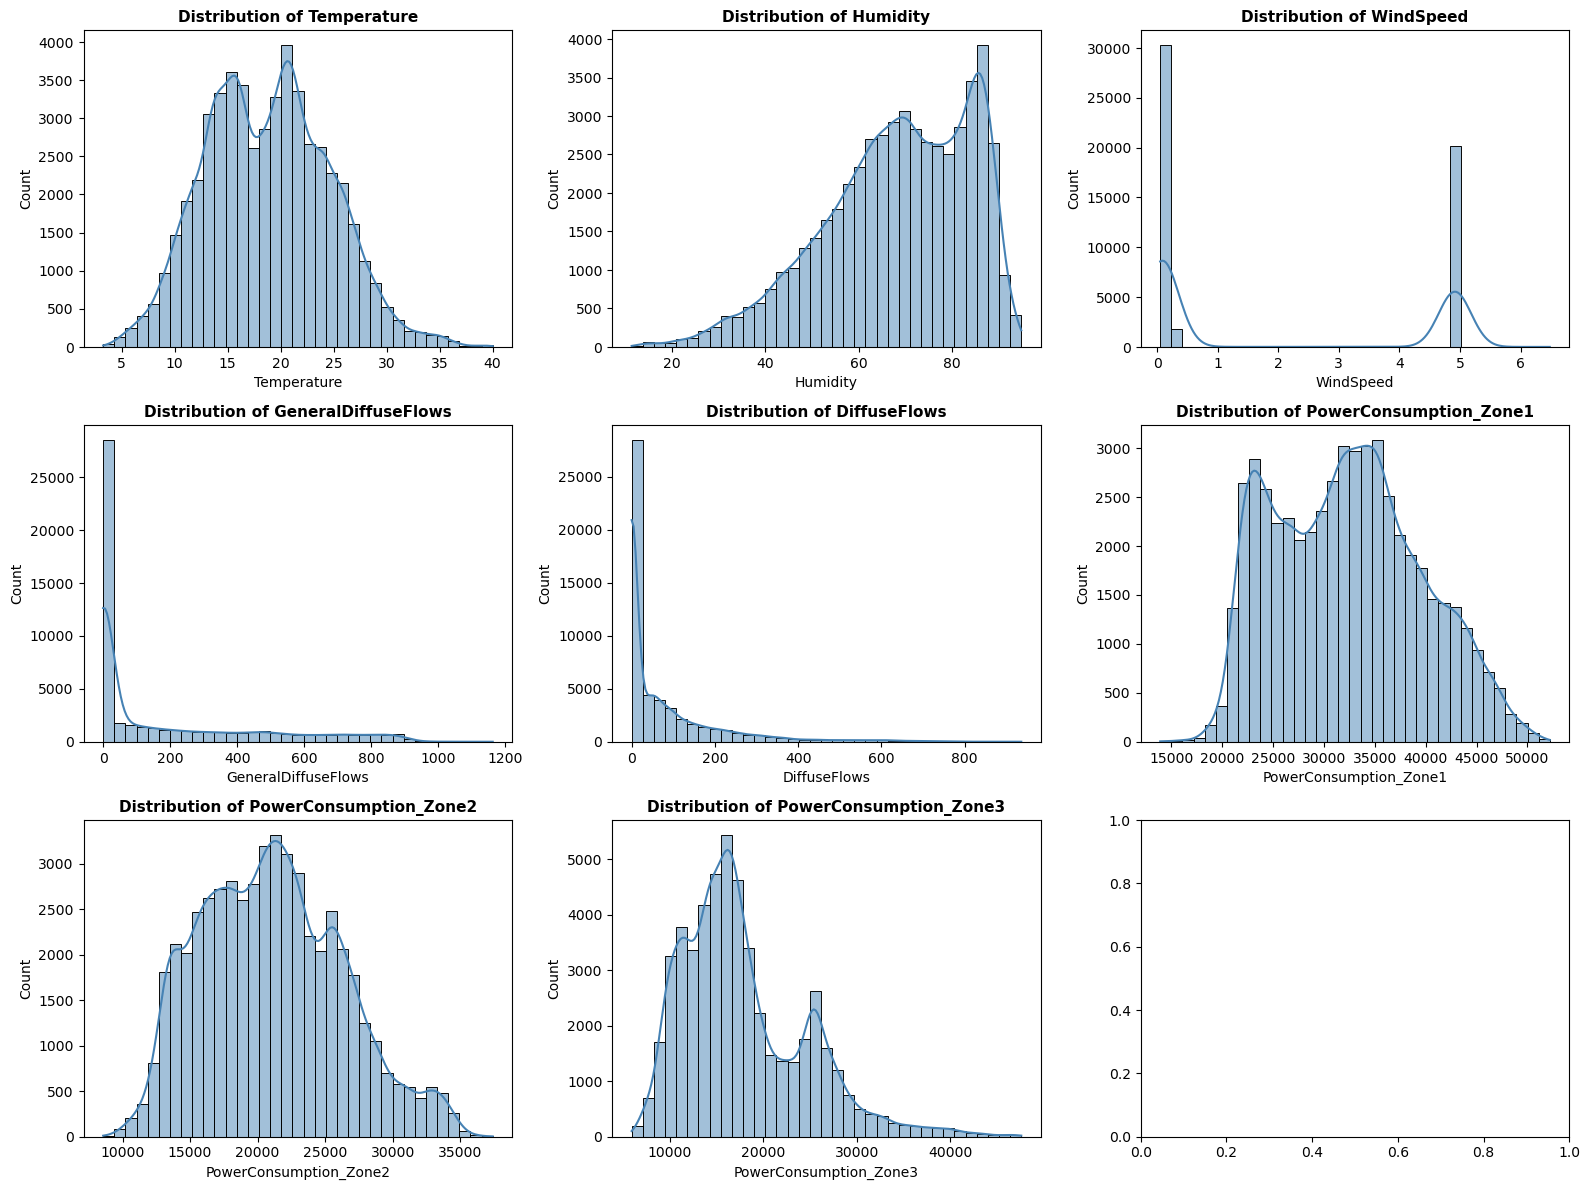

In [2]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color='steelblue', bins=35)
    axes[i].set_title(f'Distribution of {col}', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()


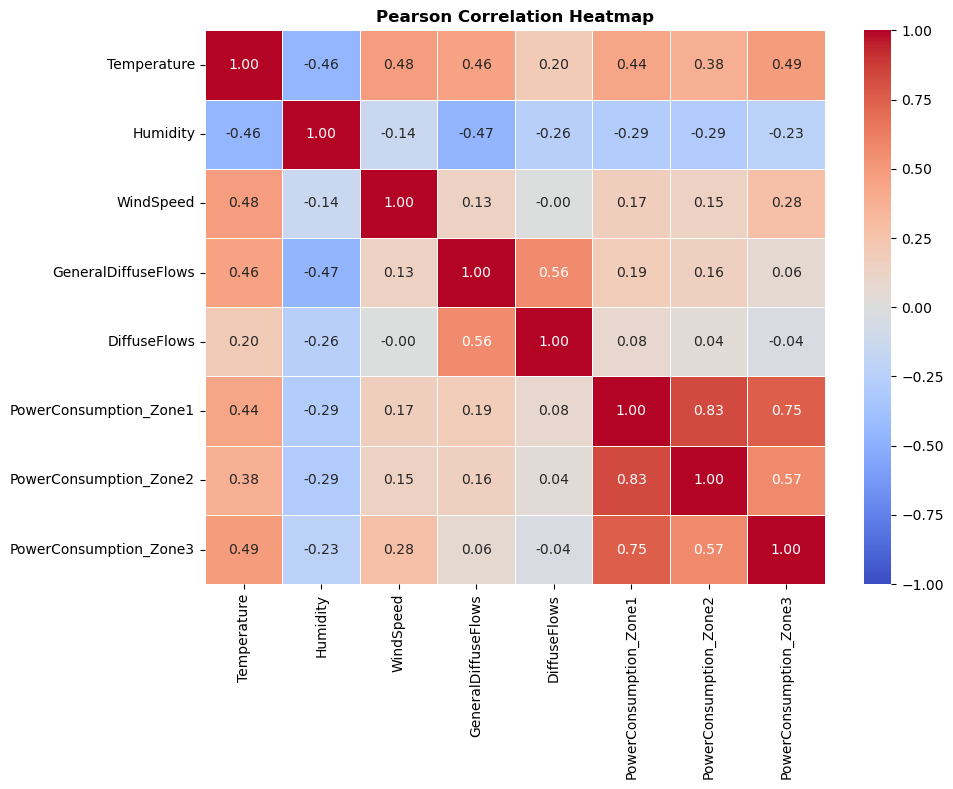

In [3]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Pearson Correlation Heatmap', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Feature Engineering
df_clean = df.copy()
df_clean['Datetime'] = pd.to_datetime(df_clean['Datetime'])
df_clean['Hour'] = df_clean['Datetime'].dt.hour
df_clean['Month'] = df_clean['Datetime'].dt.month
df_clean['DayOfWeek'] = df_clean['Datetime'].dt.dayofweek
df_clean['Day'] = df_clean['Datetime'].dt.day
df_clean['IsWeekend'] = df_clean['DayOfWeek'].apply(lambda x: 1 if x >= 5 else 0)
df_clean['IsNight'] = df_clean['Hour'].apply(lambda x: 1 if (x < 6 or x > 22) else 0)
df_clean['Temp_Humidity_Index'] = df_clean['Temperature'] * (df_clean['Humidity'] / 100.0)
df_clean['Total_Diffuse_Flows'] = df_clean['GeneralDiffuseFlows'] + df_clean['DiffuseFlows']

feature_cols = ['Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows',
                'Hour', 'Month', 'DayOfWeek', 'Day', 'IsWeekend', 'IsNight',
                'Temp_Humidity_Index', 'Total_Diffuse_Flows']

X = df_clean[feature_cols]
y = df_clean['PowerConsumption_Zone1']

# 80:20 Train-Test Split with random_state=42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Scaler fitted strictly on X_train
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")
print("StandardScaler fitted strictly on training data (Zero Data Leakage).")


X_train shape: (41932, 13) | X_test shape: (10484, 13)
StandardScaler fitted strictly on training data (Zero Data Leakage).
